**ANOMALY DETECTION OC-SVM**

In [2]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [ ]:
job_names = ["net_v3_0per_k73", "net_v3_0per_k63", "net_v3_0per_k55", "net_v3_0per_k8"]

def load_job(job_name):
    results_dir = f"/tmp/anomaly_results_pca_{job_name}"          # una cartella per job: niente file vecchi mescolati
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_pca_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df

summary = []        # una riga per job
all_rules = {}      # tabella delle regole di ogni job

for job_name in job_names:
    results, df = load_job(job_name)
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    summary.append({
        "job_name": job_name,
        "k": results["k"],
        "varianza_spiegata": results["varianza_spiegata"],
        "min_flood_area": results["min_flood_area"],
        "standardize": results["standardize"],
        "n_fit": results["n_fit"], "n_normali": results["n_normali"], "n_anomale": results["n_anomale"],
        "score_normali": f"{score_normal.mean():.4f} ± {score_normal.std():.4f}",
        "score_anomale": f"{score_anom.mean():.4f} ± {score_anom.std():.4f}",
        "auroc": results["auroc"],
    })
    all_rules[job_name] = pd.DataFrame(results["rules"]).T

df_summary = pd.DataFrame(summary).set_index("job_name")
df_rules = pd.concat(all_rules, names=["job_name", "regola"])     # indice a due livelli: job, regola

df_summary

,k,varianza_spiegata,min_flood_area,standardize,n_fit,n_normali,n_anomale,score_normali,score_anomale,auroc
job_name,,,,,,,,,,
net_v3_0per_k55,55,0.902910,0.0,True,2572,2402,2402,-26.8186 ± 9.9551,-33.1581 ± 12.1120,0.659215
net_v3_0per_k8,8,0.291003,0.0,True,2572,2402,2402,-182.8901 ± 41.3663,-213.9603 ± 40.6572,0.705973


In [15]:
df_rules

soglia      TP  \
job_name        regola                                                    
net_v3_0per_k55 pca score < soglia (FA 5%)           -45.282417   361.0   
                pca score < soglia (FA 10%)          -40.394550   578.0   
                pca score < soglia (FA 15%)          -37.088875   763.0   
                pca score < soglia (FA 20%)          -34.842964   926.0   
                pca score < soglia (FA 25%)          -32.717110  1116.0   
                pca score < soglia (FA 30%)          -30.774637  1249.0   
net_v3_0per_k8  pca residuo score < soglia (FA 5%)  -250.115112   450.0   
                pca residuo score < soglia (FA 10%) -235.061371   725.0   
                pca residuo score < soglia (FA 15%) -226.528595   916.0   
                pca residuo score < soglia (FA 20%) -218.169037  1104.0   
                pca residuo score < soglia (FA 25%) -209.870667  1324.0   
                pca residuo score < soglia (FA 30%) -203.801910  1459.0   

                                                        FP      FN      TN  \
job_name        regola                                                       
net_v3_0per_k55 pca score < soglia (FA 5%)            58.0  2041.0  1143.0   
                pca score < soglia (FA 10%)          118.0  1824.0  1083.0   
                pca score < soglia (FA 15%)          189.0  1639.0  1012.0   
                pca score < soglia (FA 20%)          250.0  1476.0   951.0   
                pca score < soglia (FA 25%)          296.0  1286.0   905.0   
                pca score < soglia (FA 30%)          360.0  1153.0   841.0   
net_v3_0per_k8  pca residuo score < soglia (FA 5%)    79.0  1952.0  1122.0   
                pca residuo score < soglia (FA 10%)  143.0  1677.0  1058.0   
                pca residuo score < soglia (FA 15%)  189.0  1486.0  1012.0   
                pca residuo score < soglia (FA 20%)  253.0  1298.0   948.0   
                pca residuo score < soglia (FA 25%)  324.0  1078.0   877.0   
                pca residuo score < soglia (FA 30%)  370.0   943.0   831.0   

                                                      FA_rate   MA_rate  \
job_name        regola                                                    
net_v3_0per_k55 pca score < soglia (FA 5%)           0.048293  0.849709   
                pca score < soglia (FA 10%)          0.098251  0.759367   
                pca score < soglia (FA 15%)          0.157369  0.682348   
                pca score < soglia (FA 20%)          0.208160  0.614488   
                pca score < soglia (FA 25%)          0.246461  0.535387   
                pca score < soglia (FA 30%)          0.299750  0.480017   
net_v3_0per_k8  pca residuo score < soglia (FA 5%)   0.065779  0.812656   
                pca residuo score < soglia (FA 10%)  0.119067  0.698168   
                pca residuo score < soglia (FA 15%)  0.157369  0.618651   
                pca residuo score < soglia (FA 20%)  0.210658  0.540383   
                pca residuo score < soglia (FA 25%)  0.269775  0.448793   
                pca residuo score < soglia (FA 30%)  0.308077  0.392590   

                                                          REC      PREC  \
job_name        regola                                                    
net_v3_0per_k55 pca score < soglia (FA 5%)           0.150291  0.861575   
                pca score < soglia (FA 10%)          0.240633  0.830460   
                pca score < soglia (FA 15%)          0.317652  0.801471   
                pca score < soglia (FA 20%)          0.385512  0.787415   
                pca score < soglia (FA 25%)          0.464613  0.790368   
                pca score < soglia (FA 30%)          0.519983  0.776259   
net_v3_0per_k8  pca residuo score < soglia (FA 5%)   0.187344  0.850662   
                pca residuo score < soglia (FA 10%)  0.301832  0.835253   
                pca residuo score < soglia (FA 15%)  0.381349  0.828959   
                pca residuo score < s

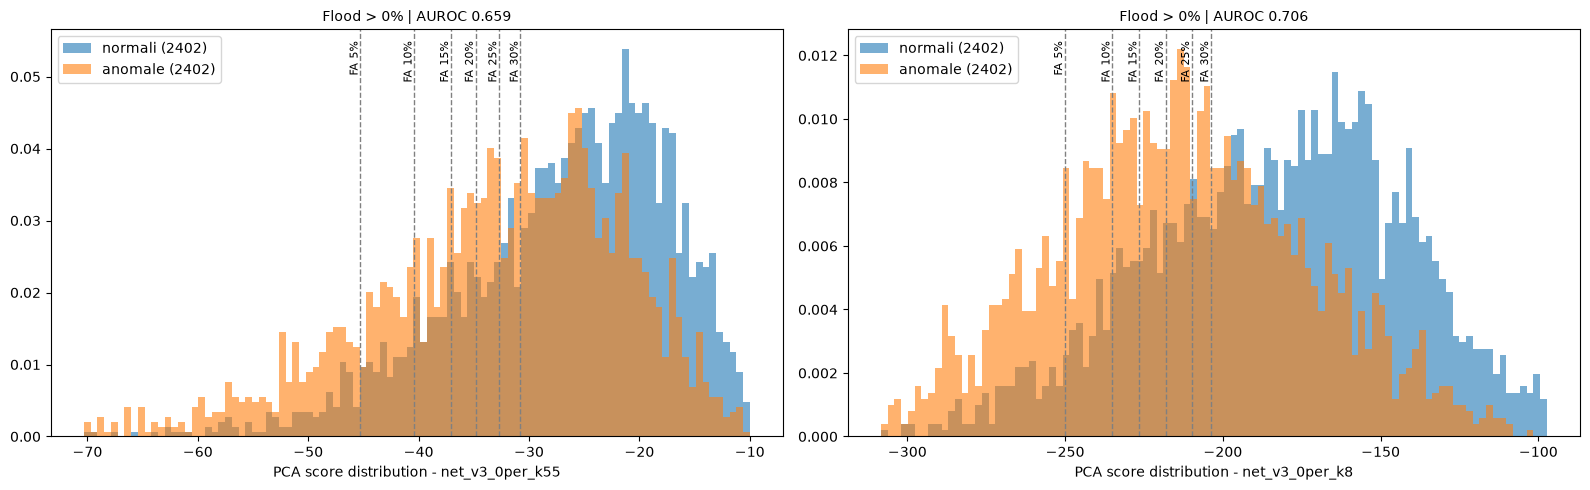

In [13]:
def plot_hist(ax, job_name, results, df):
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])               # si taglia lo 0.5% piu' estremo per lato
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
    for nome, r in results["rules"].items():                     # una riga tratteggiata per ogni soglia salvata nel json
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)
    ax.set_xlabel(f"PCA score distribution - {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=10)


n_cols = 2
n_rows = int(np.ceil(len(job_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows), squeeze=False)

for ax, job_name in zip(axes.flat, job_names):
    results, df = load_job(job_name)
    plot_hist(ax, job_name, results, df)

for ax in axes.flat[len(job_names):]:                           # spegne i riquadri vuoti se i job sono dispari
    ax.axis("off")

plt.tight_layout()
plt.show()

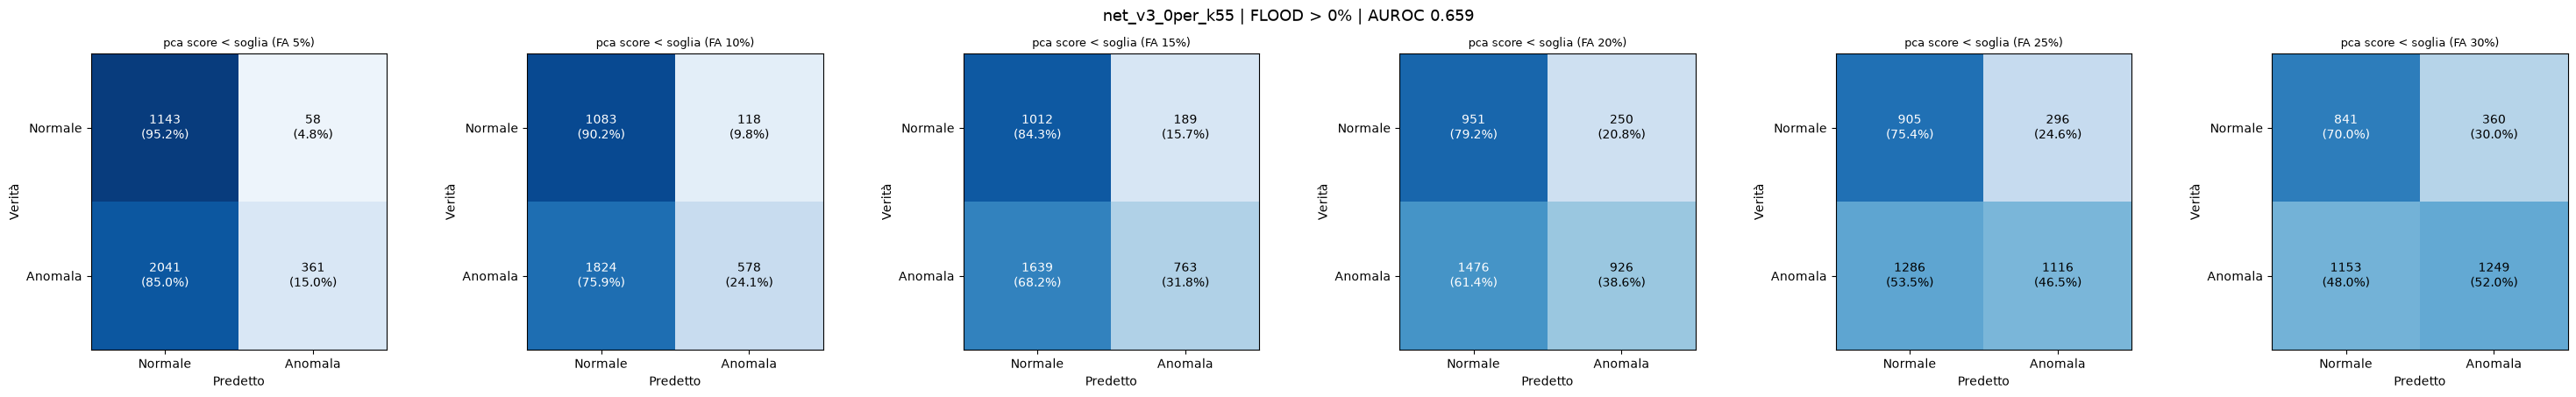

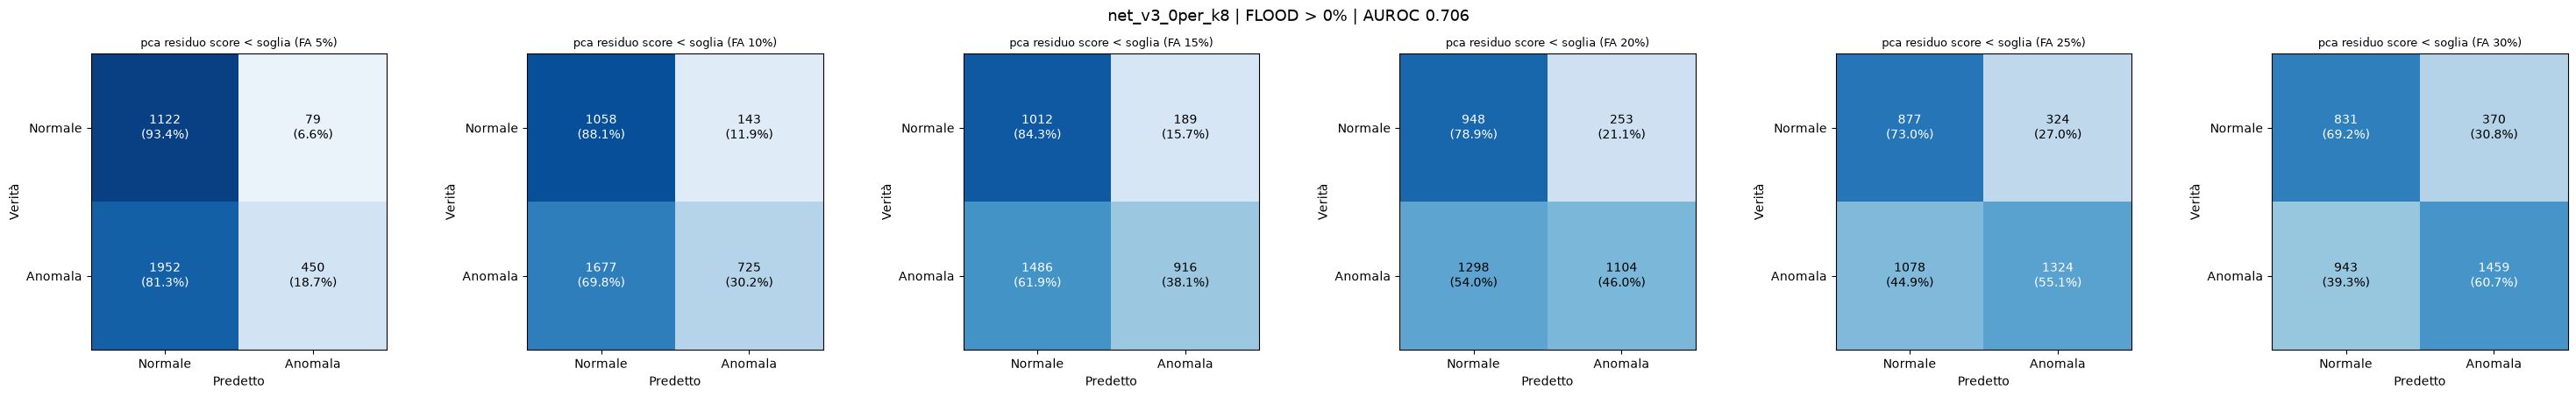

In [14]:
def plot_confusion(job_name, results):
    rules = results["rules"]
    fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

    for ax, (nome, r) in zip(axes[0], rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    fig.suptitle(f"{job_name} | FLOOD > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
    plt.tight_layout()
    plt.show()


for job_name in job_names:
    results, df = load_job(job_name)
    plot_confusion(job_name, results)